# E-commerce Customer Churn Prediction

Data preparation, exploratory analysis and a CART decision tree model to identify drivers of customer churn. Place `ECA_churn.csv` in the same folder before running.

## 1. Data exploration

In [1]:
import pandas as pd

df = pd.read_csv("ECA_churn.csv")

# First few rows of dataset
print(df.head())

# Check dimensions, columns, and data types
print("Shape:", df.shape)
print(df.info())

# Summary stats and missing values per column
print(df.describe())
print(df.isnull().sum())

   Customer ID StockCode  Quantity  Price         Country  Customer_Age  \
0            1     22457         6   2.95  United Kingdom            63   
1            2     84946        12   1.25  United Kingdom            33   
2            3    84760S        12   1.45  United Kingdom            59   
3            4     22423         2  12.75  United Kingdom            72   
4            5     22784         3   4.95  United Kingdom            35   

   Gender Customer_Segment Marketing_Channel     Category Subcategory  \
0    Male          Regular          Referral   Home Decor      Frames   
1    Male          Regular               Ads  Electronics     Gadgets   
2    Male              New          Referral     Clothing        Kids   
3  Female              New             Email      Kitchen  Appliances   
4  Female          Regular               Ads      Kitchen     Storage   

  Discount_Applied Payment_Method  Delivery_Time_Days Churn_Flag  
0               no           Cash          

### Inspect Customer_Segment

In [2]:
# Explore Customer_Segment column
print("Unique values in Customer_Segment: ", df['Customer_Segment'].unique())
print("Value counts:\n", df['Customer_Segment'].value_counts(dropna=False))

Unique values in Customer_Segment:  <StringArray>
['Regular', 'New', 'VIP', nan, 'Missing?']
Length: 5, dtype: str
Value counts:
 Customer_Segment
VIP         1002
Regular      996
New          996
NaN          343
Missing?      68
Name: count, dtype: int64


### Treat missing values

In [3]:
# Replace "Missing?" with NaN
df['Customer_Segment'] = df['Customer_Segment'].replace("Missing?", pd.NA)

# Replace missing values with mode
df['Customer_Segment'] = df['Customer_Segment'].fillna(df['Customer_Segment'].mode()[0])

# Check replacements
print("Value counts:\n", df['Customer_Segment'].value_counts(dropna=False))

Value counts:
 Customer_Segment
VIP        1413
Regular     996
New         996
Name: count, dtype: int64


### Detect and remove outliers (IQR method)

In [4]:
# Detect and treat outliers
def remove_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return dataframe[(dataframe[column] >= lower_bound) & (dataframe[column] <= upper_bound)]

# Before cleaning
print("Before cleaning:")
for col in ["Quantity", "Price", "Customer_Age", "Delivery_Time_Days"]:
    print(f"{col} -> Min: {df[col].min()}, Max: {df[col].max()}")

print("Shape before:", df.shape)

# Apply to numeric columns
for col in ["Quantity", "Price", "Customer_Age", "Delivery_Time_Days"]:
    df = remove_outliers_iqr(df, col)

# Check data after cleaning
print("\nAfter Cleaning:")
for col in ["Quantity", "Price", "Customer_Age", "Delivery_Time_Days"]:
    print(f"{col} -> Min: {df[col].min()}, Max: {df[col].max()}")

print(df.shape)

Before cleaning:
Quantity -> Min: 1, Max: 1200
Price -> Min: 0.06, Max: 110.0
Customer_Age -> Min: 18, Max: 79
Delivery_Time_Days -> Min: 1, Max: 9
Shape before: (3405, 15)

After Cleaning:
Quantity -> Min: 1, Max: 27
Price -> Min: 0.06, Max: 7.5
Customer_Age -> Min: 18, Max: 79
Delivery_Time_Days -> Min: 1, Max: 9
(2931, 15)


### Encode categorical variables and engineer features

In [5]:
# Encode Binary Flags
df['Discount_Applied'] = df['Discount_Applied'].map({'yes': 1, 'no': 0})
df['Churn_Flag'] = df['Churn_Flag'].map({'churned': 1, 'active': 0})

# Encode Category Variables and show mappings
categorical_cols = ["Country", "Gender", "Customer_Segment", "Marketing_Channel", "Category", "Subcategory", "Payment_Method"]

for col in categorical_cols:
    df[col] = df[col].astype('category')
    mapping = dict(enumerate(df[col].cat.categories))
    print(f"\nColumn: {col}")
    print("Mapping (code → category):", mapping)
    print("Unique codes in data:", df[col].cat.codes.unique())
    df[col] = df[col].cat.codes

# New Variables
df['Total_Spend'] = df['Quantity'] * df['Price']
df['Avg_Spend_Per_Item'] = df['Total_Spend'] / df['Quantity']
df['Is_Frequent_Buyer'] = (df['Quantity'] > 10).astype(int)

print("\nPreview of new variables:\n", 
      df[['Quantity', 'Price', 'Total_Spend', 'Avg_Spend_Per_Item', 'Is_Frequent_Buyer']].head())

# Remove outliers 
for col in ["Total_Spend", "Avg_Spend_Per_Item"]:
    df = remove_outliers_iqr(df, col)

# Check dataset cleaning
print("\nRanges after cleaning engineered features:")
for col in ["Total_Spend", "Avg_Spend_Per_Item"]:
    print(f"{col} -> Min: {df[col].min()}, Max: {df[col].max()}")

print(df[['Discount_Applied','Churn_Flag']].head())
print(df[['Quantity','Price','Total_Spend','Avg_Spend_Per_Item','Is_Frequent_Buyer']].head())
print(df['Churn_Flag'].value_counts())


Column: Country
Mapping (code → category): {0: 'Australia', 1: 'Bahrain', 2: 'Canada', 3: 'France', 4: 'Germany', 5: 'Ireland', 6: 'Italy', 7: 'Netherlands', 8: 'Sweden', 9: 'Switzerland', 10: 'United Kingdom'}
Unique codes in data: [10  0  3  4  9  5  7  2  8  6  1]

Column: Gender
Mapping (code → category): {0: 'Female', 1: 'Male'}
Unique codes in data: [1 0]

Column: Customer_Segment
Mapping (code → category): {0: 'New', 1: 'Regular', 2: 'VIP'}
Unique codes in data: [1 0 2]

Column: Marketing_Channel
Mapping (code → category): {0: 'Ads', 1: 'Email', 2: 'Organic', 3: 'Referral'}
Unique codes in data: [3 0 2 1]

Column: Category
Mapping (code → category): {0: 'Clothing', 1: 'Electronics', 2: 'Home Decor', 3: 'Home_Decor', 4: 'Kitchen', 5: 'Stationery', 6: 'Toys'}
Unique codes in data: [2 1 0 4 5 6 3]

Column: Subcategory
Mapping (code → category): {0: 'Accessories', 1: 'Appliances', 2: 'Art', 3: 'Books', 4: 'Cables', 5: 'Decor', 6: 'Frames', 7: 'Gadgets', 8: 'Kids', 9: 'Lights', 10: 

## 2. Exploratory analysis\n### Single-variable ROC curves

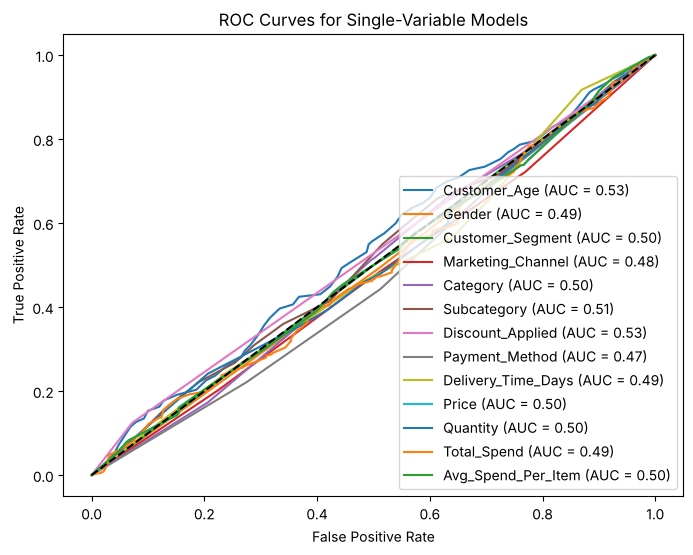

In [6]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc

def plot_variable_model(df, variable):
    if df[variable].dtype == 'object':
        X = pd.get_dummies(df[[variable]], drop_first=True)
    else:
        X = df[[variable]]
    
    y = df['Churn_Flag']
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Model
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    
    # Predict probabilities
    y_prob = model.predict_proba(X_test)[:,1]
    
    # ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, label=f'{variable} (AUC = {roc_auc:.2f})')

plt.figure(figsize=(8,6))

variables = ['Customer_Age','Gender','Customer_Segment',
             'Marketing_Channel','Category','Subcategory',
             'Discount_Applied','Payment_Method',
             'Delivery_Time_Days','Price','Quantity','Total_Spend','Avg_Spend_Per_Item']

for var in variables:
    plot_variable_model(df, var)

plt.plot([0,1],[0,1],'k--')  # baseline
plt.title("ROC Curves for Single-Variable Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.show()

### Correlation heatmap

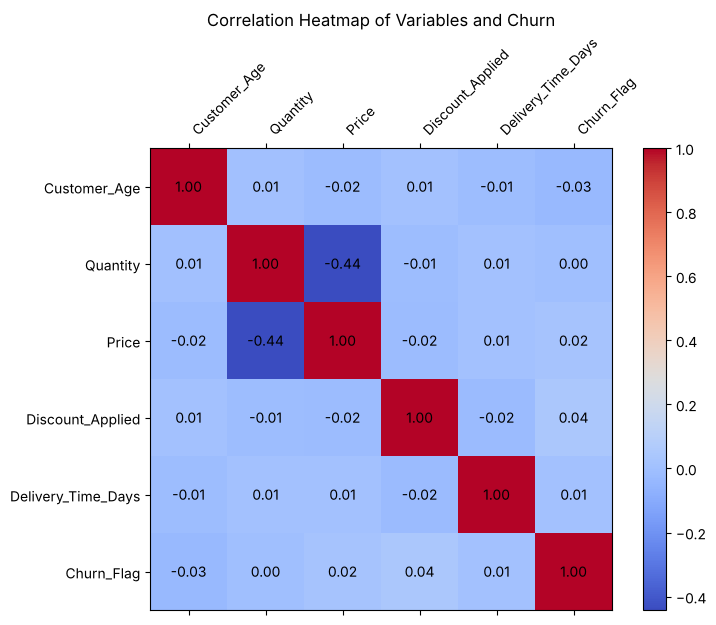

In [7]:
import numpy as np

numeric_vars = ['Customer_Age','Quantity','Price',
                'Discount_Applied','Delivery_Time_Days',
                'Churn_Flag']

corr = df[numeric_vars].corr()

fig, ax = plt.subplots(figsize=(8,6))
cax = ax.matshow(corr, cmap='coolwarm')

fig.colorbar(cax)

ax.set_xticks(np.arange(len(numeric_vars)))
ax.set_yticks(np.arange(len(numeric_vars)))
ax.set_xticklabels(numeric_vars, rotation=45, ha='left')
ax.set_yticklabels(numeric_vars)

# Annotate
for i in range(len(numeric_vars)):
    for j in range(len(numeric_vars)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", va='center', ha='center', color='black')

plt.title("Correlation Heatmap of Variables and Churn")
plt.show()

### Churn by customer segment

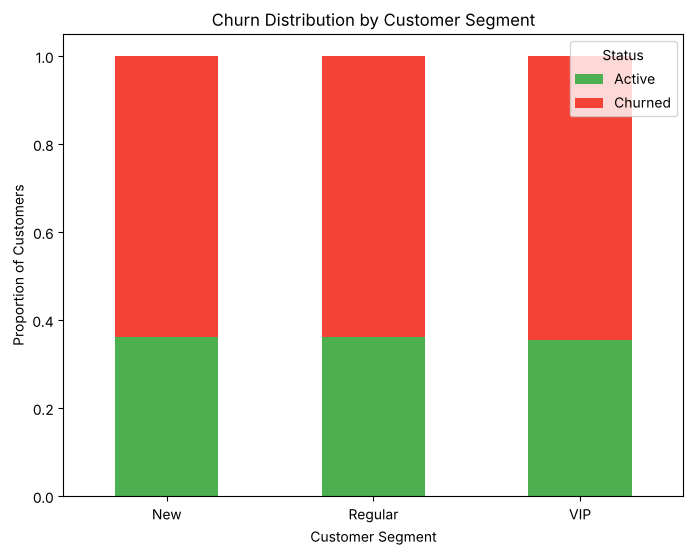

In [8]:
segment_map = {0: 'New', 1: 'Regular', 2: 'VIP'}
df['Customer_Segment_Label'] = df['Customer_Segment'].map(segment_map)

churn_segment = pd.crosstab(df['Customer_Segment_Label'], df['Churn_Flag'], normalize='index')

churn_segment.columns = ['Active', 'Churned']

churn_segment.plot(kind='bar', stacked=True,
                   color=['#4CAF50', '#F44336'],
                   figsize=(8,6))

plt.title("Churn Distribution by Customer Segment")
plt.ylabel("Proportion of Customers")
plt.xlabel("Customer Segment")
plt.legend(title="Status")
plt.xticks(rotation=0)
plt.show()

### Chi-square tests

In [9]:
from scipy.stats import chi2_contingency

categorical_cols = ["Country", "Gender", "Customer_Segment", 
                    "Marketing_Channel", "Category", 
                    "Subcategory", "Payment_Method"]

results = {}

for col in categorical_cols:
    table = pd.crosstab(df[col], df['Churn_Flag'])
    chi2, p, dof, expected = chi2_contingency(table)
    results[col] = {"Chi2": chi2, "p-value": p, "dof": dof}

# Display results
for col, stats in results.items():
    print(f"{col}: Chi2 = {stats['Chi2']:.2f}, p-value = {stats['p-value']:.4f}, dof = {stats['dof']}")

Country: Chi2 = 8.55, p-value = 0.5751, dof = 10
Gender: Chi2 = 0.39, p-value = 0.5328, dof = 1
Customer_Segment: Chi2 = 0.09, p-value = 0.9553, dof = 2
Marketing_Channel: Chi2 = 0.47, p-value = 0.9247, dof = 3
Category: Chi2 = 4.88, p-value = 0.5595, dof = 6
Subcategory: Chi2 = 20.04, p-value = 0.2186, dof = 16
Payment_Method: Chi2 = 0.98, p-value = 0.8053, dof = 3


## 3. CART model at different tree depths

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

X = df.drop(['Churn_Flag','StockCode','Customer_Segment_Label'], axis=1)
y = df['Churn_Flag']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Model: CART")
depths = [3, 5, 7, 10]
results = []

for d in depths:
    # CART Model
    model = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    model.fit(X_train, y_train)

    # Training Set Results
    train_pred = model.predict(X_train)
    train_prob = model.predict_proba(X_train)[:,1]
    train_acc = accuracy_score(y_train, train_pred)
    train_auc = roc_auc_score(y_train, train_prob)

    # Testing Set Results
    test_pred = model.predict(X_test)
    test_prob = model.predict_proba(X_test)[:,1]
    test_acc = accuracy_score(y_test, test_pred)
    test_auc = roc_auc_score(y_test, test_prob)

    results.append((d, train_acc, train_auc, test_acc, test_auc))

for r in results:
    print(f"Depth {r[0]}: "
          f"Train Accuracy={r[1]:.3f}, Train ROC-AUC={r[2]:.3f} | "
          f"Test Accuracy={r[3]:.3f}, Test ROC-AUC={r[4]:.3f}")

Model: CART
Depth 3: Train Accuracy=0.651, Train ROC-AUC=0.559 | Test Accuracy=0.629, Test ROC-AUC=0.502
Depth 5: Train Accuracy=0.670, Train ROC-AUC=0.617 | Test Accuracy=0.609, Test ROC-AUC=0.510
Depth 7: Train Accuracy=0.702, Train ROC-AUC=0.691 | Test Accuracy=0.613, Test ROC-AUC=0.530
Depth 10: Train Accuracy=0.758, Train ROC-AUC=0.811 | Test Accuracy=0.584, Test ROC-AUC=0.527


## 4. Final decision tree (depth 7)

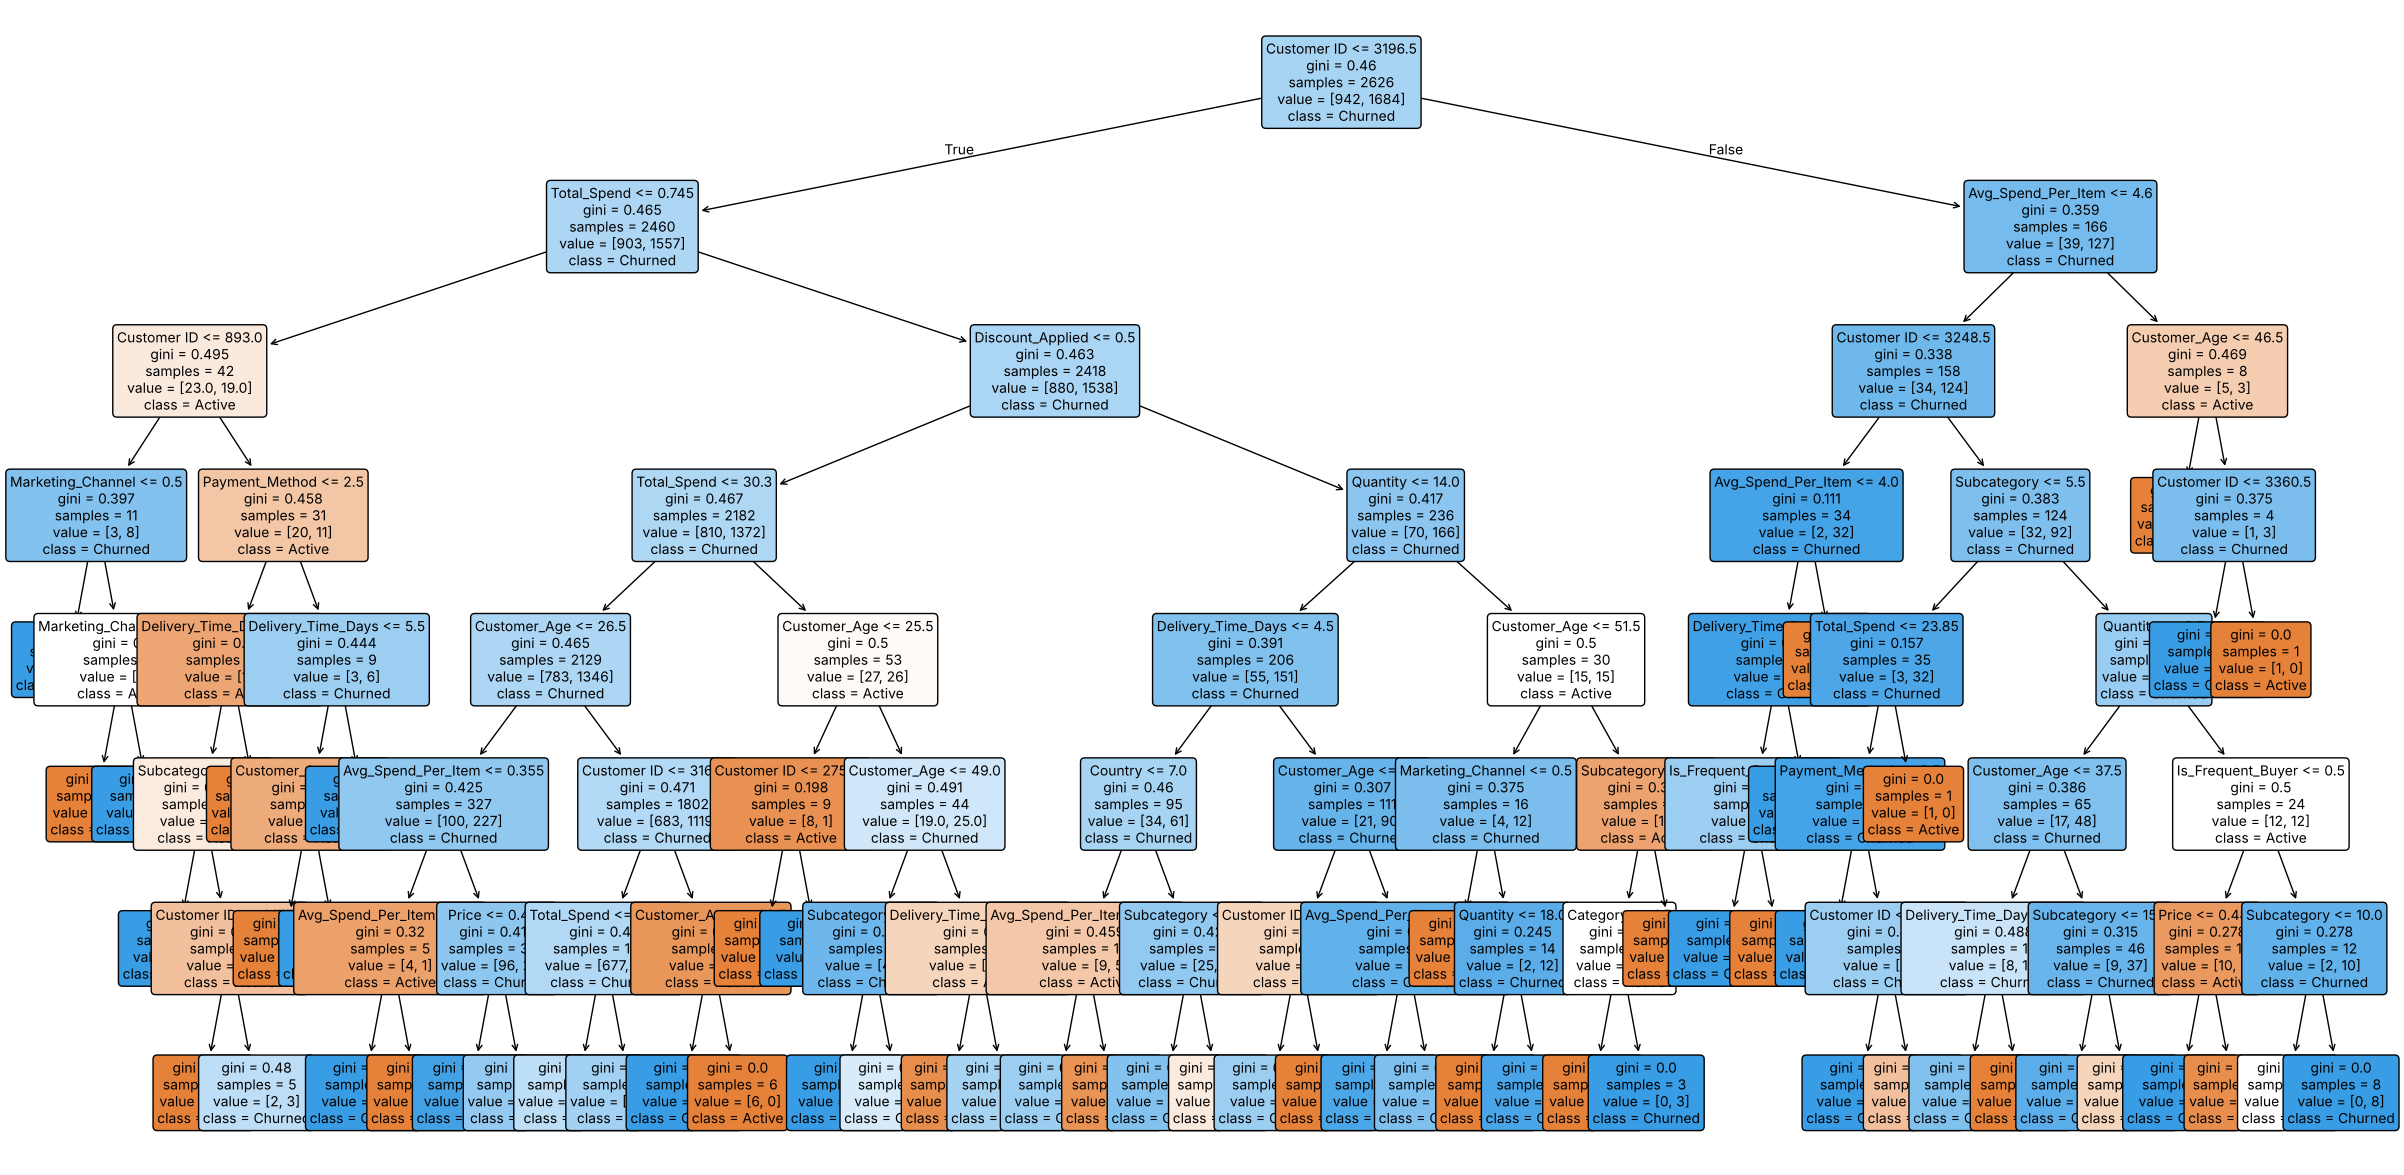

|--- Customer ID <= 3196.50
|   |--- Total_Spend <= 0.74
|   |   |--- Customer ID <= 893.00
|   |   |   |--- Marketing_Channel <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Marketing_Channel >  0.50
|   |   |   |   |--- Marketing_Channel <= 1.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Marketing_Channel >  1.50
|   |   |   |   |   |--- class: 1
|   |   |--- Customer ID >  893.00
|   |   |   |--- Payment_Method <= 2.50
|   |   |   |   |--- Delivery_Time_Days <= 4.50
|   |   |   |   |   |--- Subcategory <= 4.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- Subcategory >  4.50
|   |   |   |   |   |   |--- Customer ID <= 1477.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- Customer ID >  1477.50
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- Delivery_Time_Days >  4.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- Payment_Method >  2.50
|   |   |   |   |--- Delivery_Time_Days <= 5.50
|   |   |   |   |   |

In [11]:
from sklearn.tree import plot_tree, export_text

X = df.drop(['Churn_Flag','StockCode','Customer_Segment_Label'], axis=1)
y = df['Churn_Flag']

# 100% of model
model = DecisionTreeClassifier(max_depth=7, criterion='gini', random_state=42)
model.fit(X, y)

plt.figure(figsize=(30,15))
plot_tree(model, 
          feature_names=X.columns, 
          class_names=['Active','Churned'], 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.show()

tree_rules = export_text(model, feature_names=list(X.columns))
print(tree_rules)